In [1]:
import os
import sys
import glob
import time
import json
import warnings
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

In [2]:
class Config:
    SEED = 42
    TEST_SIZE = 0.2
    
    LGBM_PARAMS = {
        'objective': 'regression',
        'metric': 'rmse',
        'boosting_type': 'gbdt',
        'learning_rate': 0.05,
        'num_leaves': 31,
        'max_depth': 8,
        'feature_fraction': 0.8,
        'bagging_fraction': 0.8,
        'bagging_freq': 5,
        'n_estimators': 500,
        'random_state': 42,
        'n_jobs': -1
    }
    
    BASE_DIR = "/kaggle/input/datasets/akshatgupta7/crop-yield-in-indian-states-dataset"
    if not os.path.exists(BASE_DIR):
        _alt = glob.glob("/kaggle/input/*yield*")
        BASE_DIR = _alt[0] if _alt else "./crop-yield-dataset"
        
    OUT_DIR = "./output/phase_1_4"
    MODEL_DIR = os.path.join(OUT_DIR, "models")
    PLOT_DIR = os.path.join(OUT_DIR, "plots")
    
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(PLOT_DIR, exist_ok=True)

def seed_everything(seed):
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

seed_everything(Config.SEED)
print(f"Phase 1.4 Configuration Loaded. Target Directory: {Config.OUT_DIR}")

Phase 1.4 Configuration Loaded. Target Directory: ./output/phase_1_4


In [3]:
print("\n--- Starting Dataset Discovery & Verification ---")
try:
    csv_path = os.path.join(Config.BASE_DIR, "crop_yield.csv")
    if not os.path.exists(csv_path):
        files = glob.glob(os.path.join(Config.BASE_DIR, "*.csv"))
        if not files:
            raise FileNotFoundError(f"Dataset missing in {Config.BASE_DIR}.")
        csv_path = files[0]
        
    df_raw = pd.read_csv(csv_path)
    
    # Standardizing column names for safety
    df_raw.columns = [col.strip() for col in df_raw.columns]
    
    # Filter strictly for Rice/Paddy
    df_rice = df_raw[df_raw['Crop'].str.lower() == 'rice'].copy()
    
    verification_report = {
        "original_rows": len(df_raw),
        "rice_rows": len(df_rice),
        "total_columns": len(df_rice.columns),
        "missing_values": df_rice.isnull().sum().to_dict(),
        "duplicate_rows": int(df_rice.duplicated().sum())
    }

    with open(os.path.join(Config.OUT_DIR, "dataset_verification.json"), "w") as f:
        json.dump(verification_report, f, indent=4)

    if verification_report["rice_rows"] == 0:
        raise ValueError("No 'Rice' samples found in dataset. Halting execution.")

    print("Dataset Verification Successful.")
    print(f"Total Rice Samples: {verification_report['rice_rows']} | Columns: {verification_report['total_columns']}")

except Exception as e:
    sys.exit(f"Verification Failed: {e}")


--- Starting Dataset Discovery & Verification ---
Dataset Verification Successful.
Total Rice Samples: 1197 | Columns: 10



--- Performing Exploratory Data Analysis ---


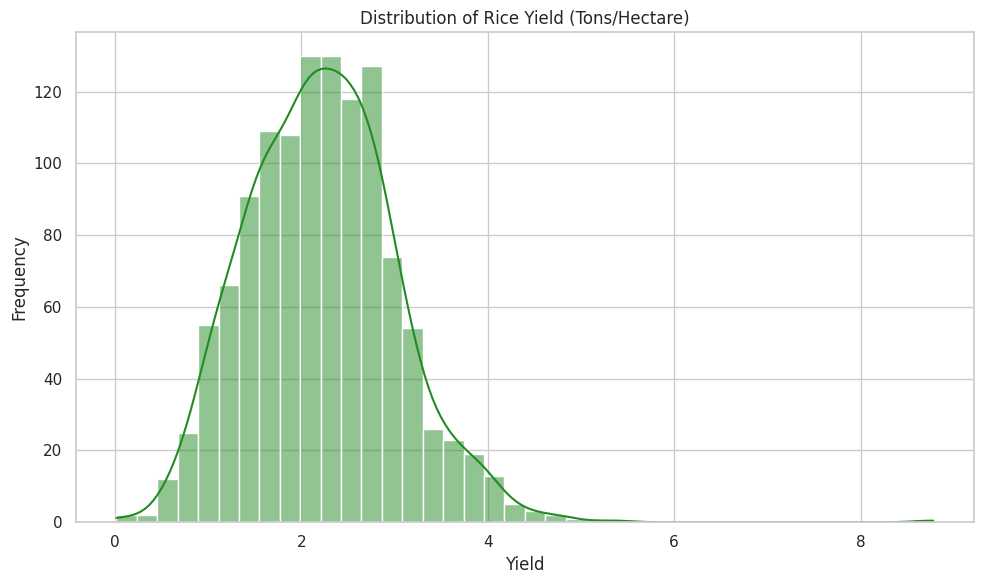

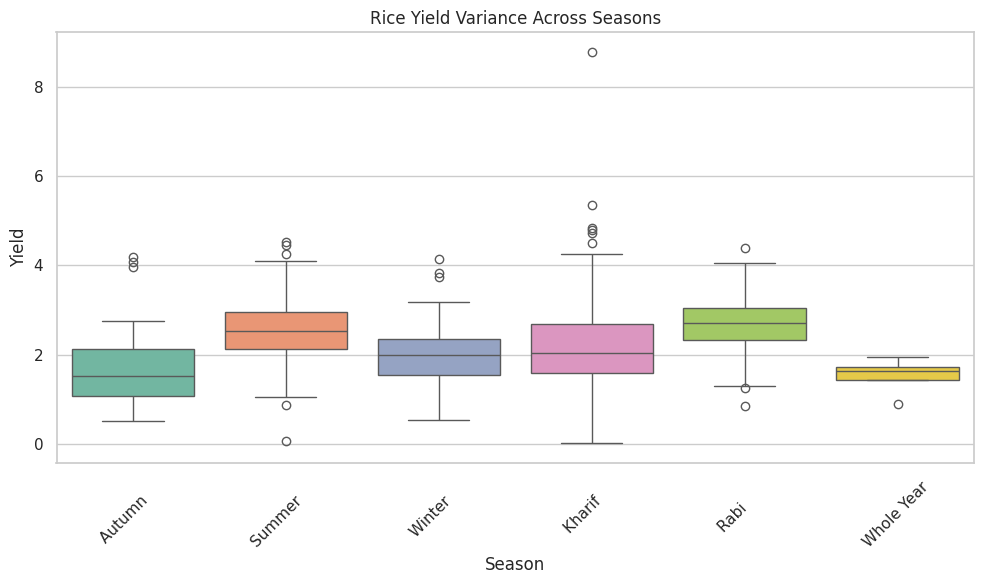

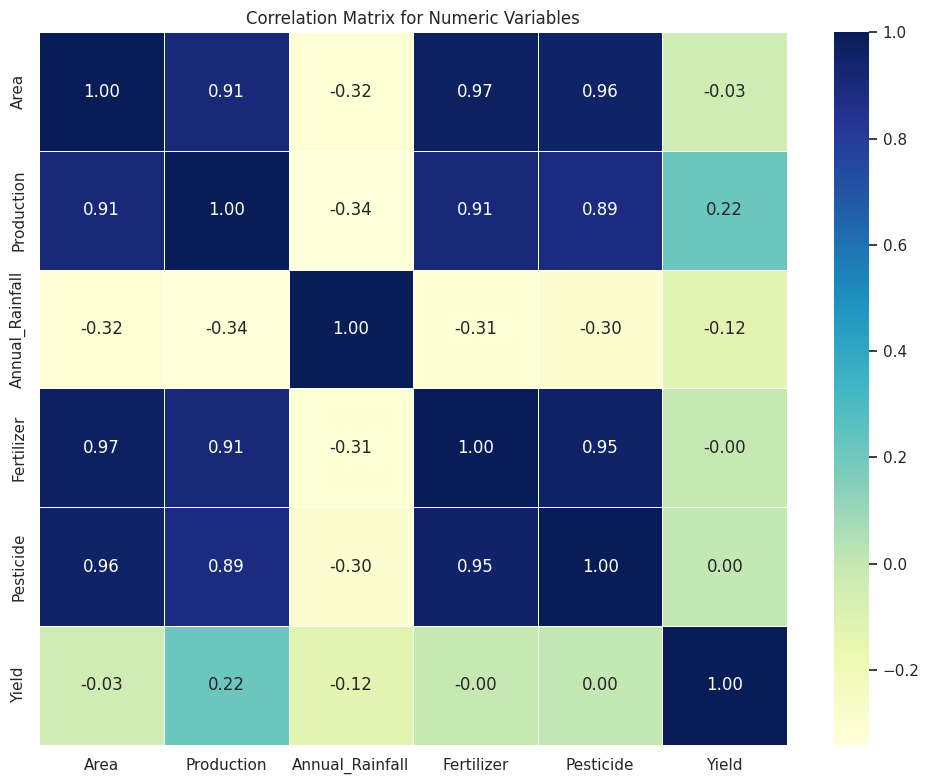

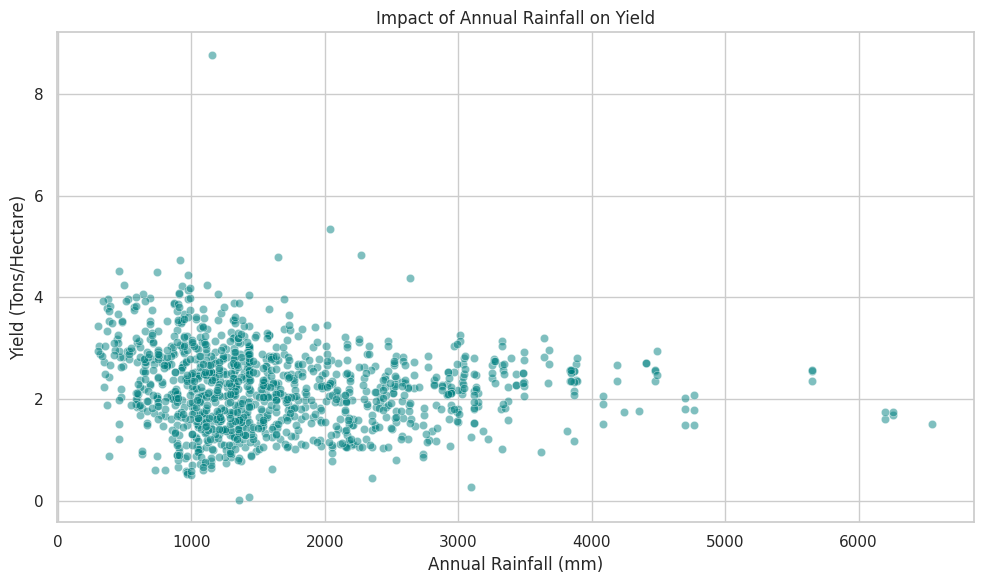

EDA completed and plots saved.


In [4]:
print("\n--- Performing Exploratory Data Analysis ---")
sns.set_theme(style="whitegrid")

# Clean duplicates for analysis
df_rice.drop_duplicates(inplace=True)

# 1. Target Distribution (Yield)
plt.figure(figsize=(10, 6))
sns.histplot(df_rice['Yield'], kde=True, color='forestgreen', bins=40)
plt.title("Distribution of Rice Yield (Tons/Hectare)")
plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "yield_distribution.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 2. Season vs Yield Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_rice, x='Season', y='Yield', palette='Set2')
plt.title("Rice Yield Variance Across Seasons")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "yield_by_season.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 3. Numeric Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_cols = ['Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
# Using only available numeric columns to prevent KeyError
available_numeric = [c for c in numeric_cols if c in df_rice.columns]
corr = df_rice[available_numeric].corr()
sns.heatmap(corr, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix for Numeric Variables")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "correlation_heatmap.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 4. Rainfall vs Yield Scatter
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_rice, x='Annual_Rainfall', y='Yield', alpha=0.5, color='teal')
plt.title("Impact of Annual Rainfall on Yield")
plt.xlabel("Annual Rainfall (mm)")
plt.ylabel("Yield (Tons/Hectare)")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "rainfall_vs_yield.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

print("EDA completed and plots saved.")

In [5]:
print("\n--- Starting Data Preprocessing ---")

df_rice.dropna(subset=['Yield', 'Annual_Rainfall', 'Fertilizer', 'Pesticide'], inplace=True)

features = ['Season', 'State', 'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']
target = 'Yield'

X = df_rice[features].copy()
y = df_rice[target].copy()

encoders = {}
categorical_cols = ['Season', 'State']

for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=Config.TEST_SIZE, random_state=Config.SEED
)

print(f"Data Prepared. Training Shape: {X_train.shape} | Testing Shape: {X_test.shape}")



--- Starting Data Preprocessing ---
Data Prepared. Training Shape: (957, 6) | Testing Shape: (240, 6)



--- Starting LightGBM Model Training ---
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000744 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1051
[LightGBM] [Info] Number of data points in the train set: 957, n

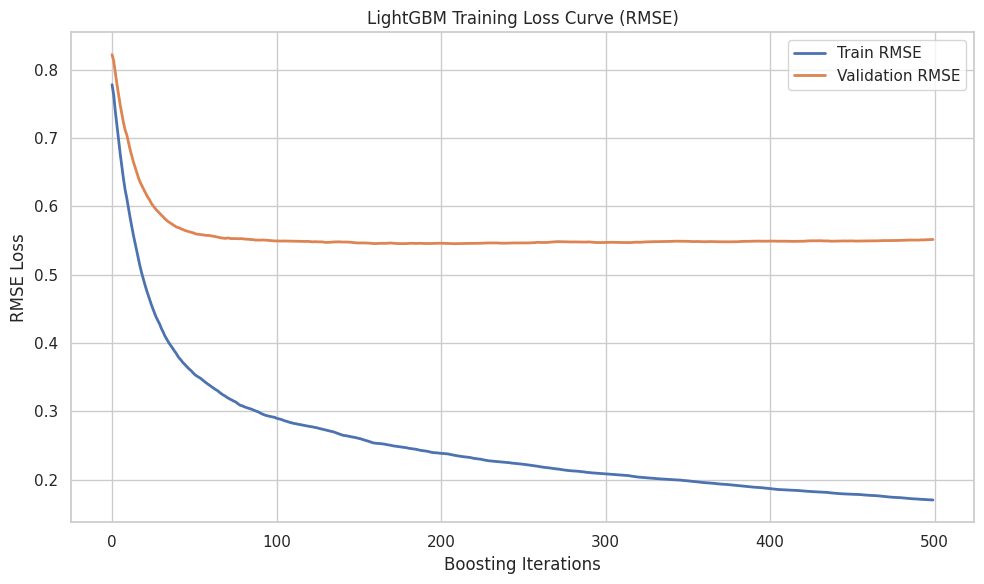

In [6]:
print("\n--- Starting LightGBM Model Training ---")

model = lgb.LGBMRegressor(**Config.LGBM_PARAMS)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    eval_names=['train', 'val'],
    callbacks=[lgb.log_evaluation(50)]
)

print("LightGBM Training Completed.")

# Extract and plot training history
evals_result = model.evals_result_
epochs = len(evals_result['train']['rmse'])
x_axis = range(0, epochs)

plt.figure(figsize=(10, 6))
plt.plot(x_axis, evals_result['train']['rmse'], label='Train RMSE', lw=2)
plt.plot(x_axis, evals_result['val']['rmse'], label='Validation RMSE', lw=2)
plt.legend()
plt.title('LightGBM Training Loss Curve (RMSE)')
plt.ylabel('RMSE Loss')
plt.xlabel('Boosting Iterations')
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "training_loss_curve.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()



--- Evaluating Model Performance ---
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
Yield Prediction Metrics -> R2: 0.5579 | RMSE: 0.5516 | MAE: 0.2581


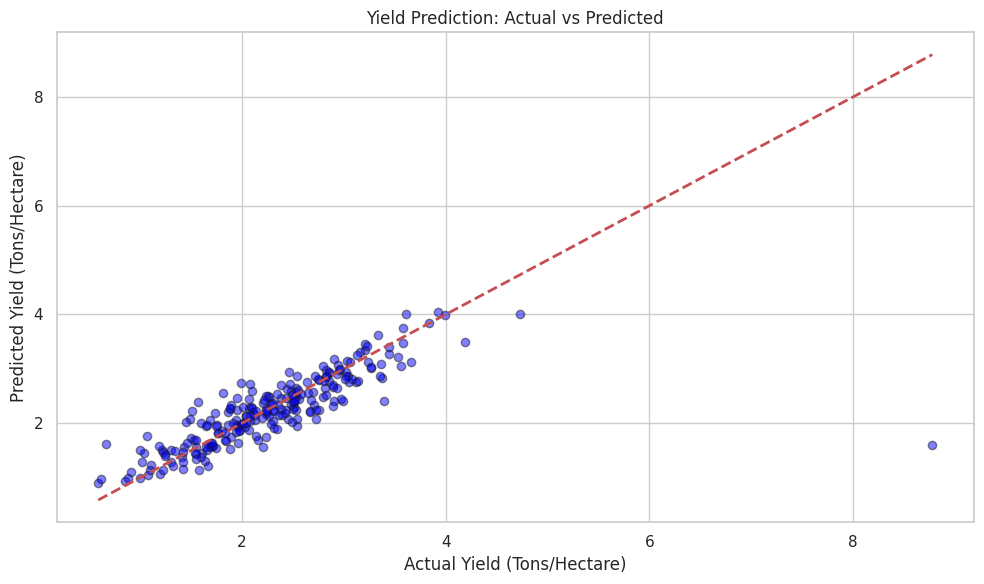

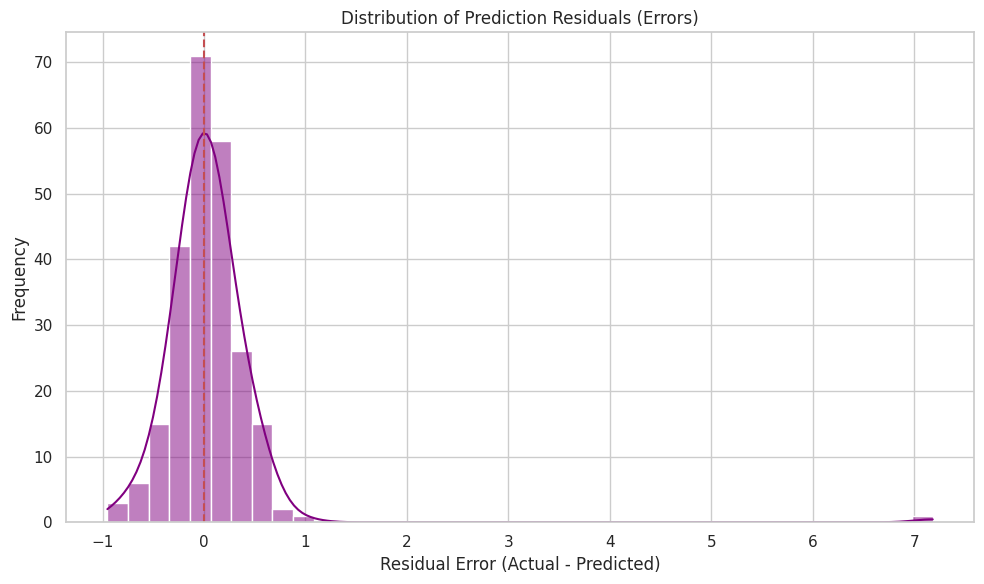

In [7]:
print("\n--- Evaluating Model Performance ---")

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"Yield Prediction Metrics -> R2: {r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

# 1. Actual vs Predicted Scatter
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Yield Prediction: Actual vs Predicted')
plt.xlabel('Actual Yield (Tons/Hectare)')
plt.ylabel('Predicted Yield (Tons/Hectare)')
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "actual_vs_predicted.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 2. Residuals Distribution
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True, color='purple', bins=40)
plt.axvline(x=0, color='r', linestyle='--')
plt.title('Distribution of Prediction Residuals (Errors)')
plt.xlabel('Residual Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "residuals_distribution.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()


--- Generating SHAP Explainability Reports ---


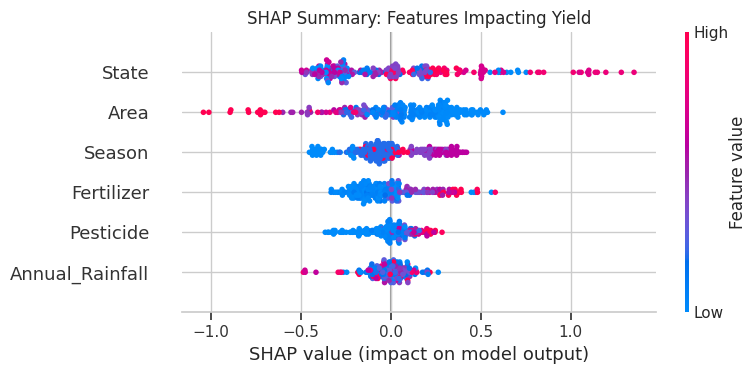

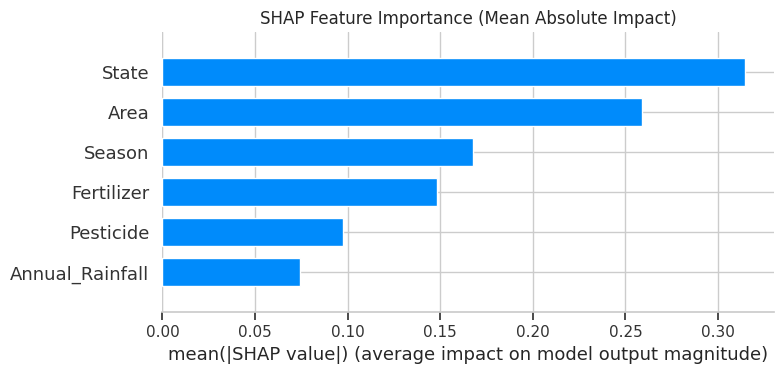

<Figure size 1000x600 with 0 Axes>

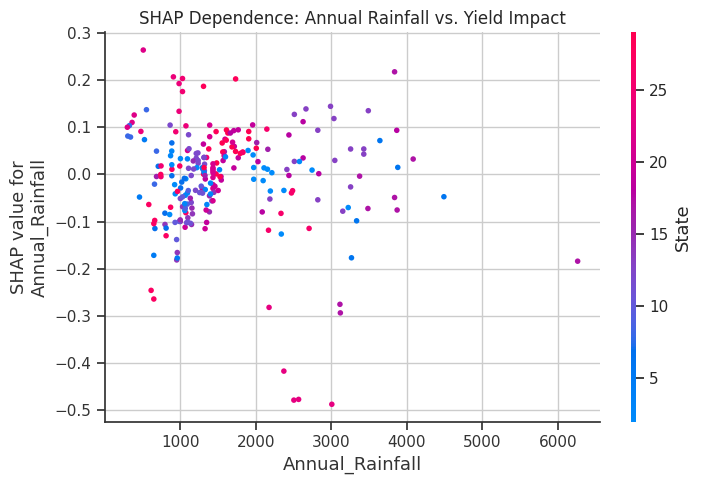

SHAP visualizations generated successfully.


In [8]:
print("\n--- Generating SHAP Explainability Reports ---")

try:
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    # 1. SHAP Summary Plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test, feature_names=features, show=False)
    plt.title("SHAP Summary: Features Impacting Yield")
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "shap_summary.png"), dpi=300, bbox_inches='tight')
    plt.show(block=False)
    plt.show()
    plt.close()

    # 2. SHAP Bar Plot (Feature Importance)
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=features, show=False)
    plt.title("SHAP Feature Importance (Mean Absolute Impact)")
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "shap_feature_importance.png"), dpi=300, bbox_inches='tight')
    plt.show(block=False)
    plt.show
    plt.close()

    # 3. SHAP Dependence Plot (Rainfall)
    plt.figure(figsize=(10, 6))
    shap.dependence_plot("Annual_Rainfall", shap_values, X_test, feature_names=features, show=False)
    plt.title("SHAP Dependence: Annual Rainfall vs. Yield Impact")
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "shap_dependence_rainfall.png"), dpi=300, bbox_inches='tight')
    plt.show(block=False)
    plt.show
    plt.close()

    print("SHAP visualizations generated successfully.")
except Exception as e:
    print(f"Warning: SHAP visualization encountered an error: {e}")

In [9]:
print("\n--- Simulating End-to-End Prediction Pipeline ---")

def simulate_profit(predicted_yield_per_hectare, area_acres, market_price_per_ton, fertilizer_kg, pesticide_kg):
    """
    Simulates the financial metrics for the dashboard.
    Converts Area to Hectares (1 Acre = 0.404686 Hectares)
    """
    area_hectares = area_acres * 0.404686
    total_production = predicted_yield_per_hectare * area_hectares
    gross_revenue = total_production * market_price_per_ton
    
    # Assume arbitrary baseline costs for simulation
    cost_fertilizer = fertilizer_kg * 30  # ₹30 per kg
    cost_pesticide = pesticide_kg * 800   # ₹800 per kg
    cost_labor = area_acres * 5000        # ₹5000 per acre
    
    total_cost = cost_fertilizer + cost_pesticide + cost_labor
    net_profit = gross_revenue - total_cost
    
    return {
        "Total Production (Tons)": round(total_production, 2),
        "Gross Revenue (INR)": round(gross_revenue, 2),
        "Total Costs (INR)": round(total_cost, 2),
        "Net Profit (INR)": round(net_profit, 2)
    }

# Take a random sample from the test set
sample_idx = X_test.index[0]
sample_features = X_test.loc[[sample_idx]]

pred_yield = model.predict(sample_features)[0]
# Use original un-encoded area for profit calculation
original_area = df_rice.loc[sample_idx, 'Area'] 
fert = sample_features['Fertilizer'].values[0]
pest = sample_features['Pesticide'].values[0]

profit_metrics = simulate_profit(pred_yield, original_area, 18500, fert, pest)

print(f"Simulated Yield: {pred_yield:.2f} Tons/Hectare")
print(f"Profit Simulation Results: {json.dumps(profit_metrics, indent=4)}")


--- Simulating End-to-End Prediction Pipeline ---
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=5, subsample_freq=0 will be ignored. Current value: bagging_freq=5
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
Simulated Yield: 2.23 Tons/Hectare
Profit Simulation Results: {
    "Total Production (Tons)": 23211.4,
    "Gross Revenue (INR)": 429410915.7,
    "Total Costs (INR)": 258310699.2,
    "Net Profit (INR)": 171100216.5
}


In [10]:
print("\n--- Exporting Artifacts ---")

with open(os.path.join(Config.MODEL_DIR, "best_yield_model.pkl"), "wb") as f:
    pickle.dump(model, f)

with open(os.path.join(Config.MODEL_DIR, "label_encoders.pkl"), "wb") as f:
    pickle.dump(encoders, f)

final_metrics = {
    "model_type": "LightGBM Regressor",
    "target": "Rice Yield (Tons/Hectare)",
    "r2_score": float(r2),
    "rmse": float(rmse),
    "mae": float(mae),
    "hyperparameters": Config.LGBM_PARAMS,
    "features_used": features
}

with open(os.path.join(Config.OUT_DIR, "final_yield_metrics.json"), "w") as f:
    json.dump(final_metrics, f, indent=4)
pd.DataFrame([final_metrics]).to_csv(os.path.join(Config.OUT_DIR, "final_yield_metrics.csv"), index=False)

zip_filename = os.path.join(Config.OUT_DIR, "Phase_1_4_Release.zip")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(Config.OUT_DIR):
        for file in files:
            if file.endswith('.zip'): 
                continue
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, Config.OUT_DIR)
            zipf.write(file_path, arcname)

print(f"\nPhase 1.4 Complete! All artifacts packaged successfully into: {zip_filename}")


--- Exporting Artifacts ---

Phase 1.4 Complete! All artifacts packaged successfully into: ./output/phase_1_4/Phase_1_4_Release.zip
